# Projet d'Apprentissage Statistique : Prédiction de la Qualité des Soudures Métalliques

**Auteurs :** Équipe Projet Machine Learning & Métallurgie  
**Institution :** CentraleSupélec  
**Cadre :** Module d'Apprentissage Statistique & Machine Learning Avancé  

---

## 1. Contexte Industriel et Problématique Métallurgique

Le soudage des aciers de construction constitue une opération critique dans de multiples industries de pointe : fabrication de monopieux et jackets pour **éoliennes offshore**, pose d'**oléoducs et gazoducs sous-marins**, fabrication d'appareils à pression et cuves nucléaires. Une rupture en service causée par un joint soudé défectueux engendre des coûts catastrophiques tant humains, environnementaux que financiers (plusieurs milliards d'euros à l'échelle du secteur).

Historiquement, la maîtrise de la qualité des soudures repose de façon quasi exclusive sur l'**expertise empirique d'ingénieurs et maîtres-soudeurs**, transmise par apprentissage de génération en génération. L'objectif de ce projet est de **développer une chaîne complète d'apprentissage automatique (Machine Learning)** capable :
1. D'extraire, formaliser et homogénéiser la connaissance experte à partir de bases de données réelles d'essais.
2. De découvrir des corrélations complexes et non-linéaires entre la composition chimique de l'acier d'apport, les paramètres opératoires thermomécaniques et les propriétés mécaniques finales.
3. D'exploiter des approches avancées de **Machine Learning Semi-Supervisé** pour valoriser les données non labellisées issues de la littérature.
4. De fournir des recommandations concrètes et directement applicables pour garantir une qualité optimale des assemblages soudés en production industrielle.

## 2. Environnement de Développement et Importation des Bibliothèques

Nous mobilisons l'écosystème scientifique standard de Python :
- `pandas`, `numpy` pour la manipulation matricielle et le data wrangling.
- `scikit-learn` pour le pré-traitement (imputation, normalisation, encodage), la réduction dimensionnelle (ACP), les modèles supervisés et les algorithmes semi-supervisés.
- `xgboost` pour le gradient boosting d'arbres décisionnels.
- `matplotlib`, `seaborn` pour les visualisations descriptives, métrologiques et diagnostiques.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-traitement et pipelines
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Validation et métriques
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

# Modèles supervisés
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neural_network import MLPRegressor
import xgboost as xgb

# Modèles semi-supervisés
from sklearn.semi_supervised import SelfTrainingClassifier, LabelSpreading

# Configuration graphique
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
plt.rcParams['figure.figsize'] = (10, 6)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


## 3. Chargement des Données et Audit Métrologique (Data Cleansing)

### Origine des données : Base WeldDB de l'Université de Cambridge
Les données utilisées proviennent de la bibliothèque publique **Materials Algorithms Project (MAP)** de l'Université de Cambridge, compilée par Tracey Cool et le Pr. H.K.D.H. Bhadeshia (*Cambridge University, Phase Transformations Group*).

### Audit critique : Détection d'un biais de locale dans `data_projet.xlsx`
En comparant le fichier fourni `data_projet.xlsx` et l'archive officielle Cambridge `welddb.tar` (`welddb.data`), une analyse approfondie révèle une anomalie critique :
- Lors de l'import originel du texte anglais dans un tableur français avec séparateur décimal par virgule, le point décimal a été interprété comme un **séparateur de milliers** ou purement tronqué sur plusieurs colonnes.
- Exemple flagrant : le carbone $C = 0.037\,\text{wt}\%$ apparaît comme $37$ (voire jusqu'à $1055$ pour $0.151\,\text{wt}\%$), la tension $U = 75.36\,\text{V}$ apparaît comme $7536\,\text{V}$, et l'apport thermique $E = 2.1\,\text{kJ/mm}$ apparaît comme $21$.
- **Justification de notre choix :** Pour préserver l'intégrité physique et thermodynamique des aciers, nous lisons directement la source officielle `welddb.data` (extraite dans le dossier) tout en restaurant la nomenclature exacte des 44 colonnes définies par la spécification MAP.

In [2]:
# Définition officielle des 44 colonnes selon la documentation WeldDB (Cool & Bhadeshia)
column_names = [
    # Éléments chimiques (Colonnes 1 à 21)
    'C', 'Si', 'Mn', 'S', 'P', 'Ni', 'Cr', 'Mo', 'V', 'Cu',
    'Co', 'W', 'O', 'Ti', 'N_elem', 'Al', 'B', 'Nb', 'Sn', 'As', 'Sb',
    # Paramètres opératoires et thermiques de soudage (Colonnes 22 à 30)
    'Current', 'Voltage', 'AC_DC', 'Polarity', 'Heat_input',
    'Interpass_temp', 'Weld_type', 'PWHT_temp', 'PWHT_time',
    # Propriétés mécaniques mesurées (Colonnes 31 à 38)
    'Yield_strength', 'Tensile_strength', 'Elongation', 'Reduction_of_area',
    'Charpy_temp', 'Charpy_energy', 'Hardness', 'FATT_50',
    # Microstructure de la zone fondue (Colonnes 39 à 43)
    'Primary_ferrite', 'Ferrite_second_phase', 'Acicular_ferrite', 'Martensite',
    'Ferrite_carbide_agg',
    # Identifiant / Référence d'essai (Colonne 44)
    'Weld_ID'
]

# Chargement direct de la source physique intègre
data_path = 'welddb_extracted/welddb.data'
if not os.path.exists(data_path):
    # Secours si welddb.data est à la racine
    data_path = 'welddb.data'

with open(data_path, 'r') as f:
    raw_lines = [line.strip().split() for line in f if line.strip()]

df = pd.DataFrame(raw_lines, columns=column_names)

# Remplacement de 'N' (valeur non rapportée en littérature) par NaN
df = df.replace('N', np.nan)

print(f"Dimensions du jeu de données brut : {df.shape[0]} lignes, {df.shape[1]} colonnes.")
df.head(5)

Dimensions du jeu de données brut : 1652 lignes, 44 colonnes.


,C,Si,Mn,S,P,Ni,Cr,Mo,V,Cu,...,Charpy_temp,Charpy_energy,Hardness,FATT_50,Primary_ferrite,Ferrite_second_phase,Acicular_ferrite,Martensite,Ferrite_carbide_agg,Weld_ID
0,0.037,0.30,0.65,0.008,0.012,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aaw
1,0.037,0.30,0.65,0.008,0.012,0,NaN,NaN,NaN,NaN,...,-28,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aawch
2,0.037,0.30,0.65,0.008,0.012,0,NaN,NaN,NaN,NaN,...,-38,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aht
3,0.037,0.31,1.03,0.007,0.014,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Baw
4,0.037,0.31,1.03,0.007,0.014,0,NaN,NaN,NaN,NaN,...,-48,100,NaN,NaN,32,28,40,0,0,Evans-Ni/CMn-1990/1991-0Bawch


## 4. Analyse et Justification du Traitement des Données

### 4.1. Typage des variables et sens de la valeur 'N'
Dans la base WeldDB, la présence du caractère `'N'` signifie **« Not Reported »** dans la publication source. Comme le soulignent expressément Cool et Bhadeshia :
> *"The presence of an 'N' indicates that the value was not reported in the publication. This is NOT meant to be an indication that the value is zero."*

Remplacer `'N'` par 0 serait une erreur métallurgique majeure (ex: une concentration d'oxygène $O=0$ ou une tension de soudage $U=0$ est physiquement impossible). Ces valeurs doivent donc impérativement être traitées comme des valeurs manquantes (`NaN`).

In [3]:
# Conversion des types numériques
num_features = [
    'C', 'Si', 'Mn', 'S', 'P', 'Ni', 'Cr', 'Mo', 'V', 'Cu',
    'Co', 'W', 'O', 'Ti', 'N_elem', 'Al', 'B', 'Nb', 'Sn', 'As',
    'Sb', 'Current', 'Voltage', 'Heat_input', 'Interpass_temp',
    'PWHT_temp', 'PWHT_time'
]

mechanical_targets = [
    'Yield_strength', 'Tensile_strength', 'Elongation', 'Reduction_of_area',
    'Charpy_temp', 'Charpy_energy', 'Hardness', 'FATT_50'
]

microstructure_targets = [
    'Primary_ferrite', 'Ferrite_second_phase', 'Acicular_ferrite', 'Martensite',
    'Ferrite_carbide_agg'
]

for col in num_features + mechanical_targets + microstructure_targets:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Harmonisation des variables catégorielles
df['AC_DC'] = df['AC_DC'].fillna('Unknown').str.strip()
df['Polarity'] = df['Polarity'].fillna('Unknown').str.strip()
df['Weld_type'] = df['Weld_type'].fillna('Unknown').str.strip().replace({
    'ShMA': 'MMA',
    'NGSAW': 'SAW-NG',
    'NGGMA': 'GMA-NG',
    'SAA': 'SA'
})

print("Résumé des cibles mécaniques disponibles :")
print(f"- Yield Strength (Limite d'élasticité Re)       : {df['Yield_strength'].notnull().sum()} essais valides ({df['Yield_strength'].notnull().mean()*100:.1f}%)")
print(f"- Tensile Strength (Résistance Rm / UTS)       : {df['Tensile_strength'].notnull().sum()} essais valides ({df['Tensile_strength'].notnull().mean()*100:.1f}%)")
print(f"- Charpy Impact Energy (Résilience aux chocs) : {df['Charpy_energy'].notnull().sum()} essais valides ({df['Charpy_energy'].notnull().mean()*100:.1f}%)")
print(f"- Elongation (Allongement à la rupture A%)    : {df['Elongation'].notnull().sum()} essais valides ({df['Elongation'].notnull().mean()*100:.1f}%)")

Résumé des cibles mécaniques disponibles :
- Yield Strength (Limite d'élasticité Re)       : 780 essais valides (47.2%)
- Tensile Strength (Résistance Rm / UTS)       : 738 essais valides (44.7%)
- Charpy Impact Energy (Résilience aux chocs) : 879 essais valides (53.2%)
- Elongation (Allongement à la rupture A%)    : 700 essais valides (42.4%)


### 4.2. Stratégie de Gestion des Valeurs Manquantes

Nous examinons la proportion de données manquantes pour chaque descripteur physico-chimique.
- **Règle de filtrage (Feature Elimination) :** Les métaux traceurs ou additifs très rares tels que le Cobalt (`Co`), le Tungstène (`W`), l'Étain (`Sn`), l'Arsenic (`As`) et l'Antimoine (`Sb`) présentent **plus de 80% à 95% de valeurs manquantes**. Imputer une telle masse d'informations créerait un artefact synthétique et introduirait un bruit néfaste sans apporter de gain prédictif. Nous décidons donc de les exclure du vecteur d'entrée, conformément à la pratique méthodologique établie par Cool et Bhadeshia (1997).
- **Règle d'imputation (Imputation Strategy) :** Pour les éléments d'alliage majeurs (Ni, Cr, Mo, V, Cu, Ti, Al, Nb) et les paramètres de soudage (Current, Voltage, Interpass), nous appliquons une **imputation par la médiane**, plus robuste aux distributions asymétriques que la moyenne, intégrée strictement au sein du pipeline d'apprentissage pour prohiber toute fuite de données (*data leakage*).

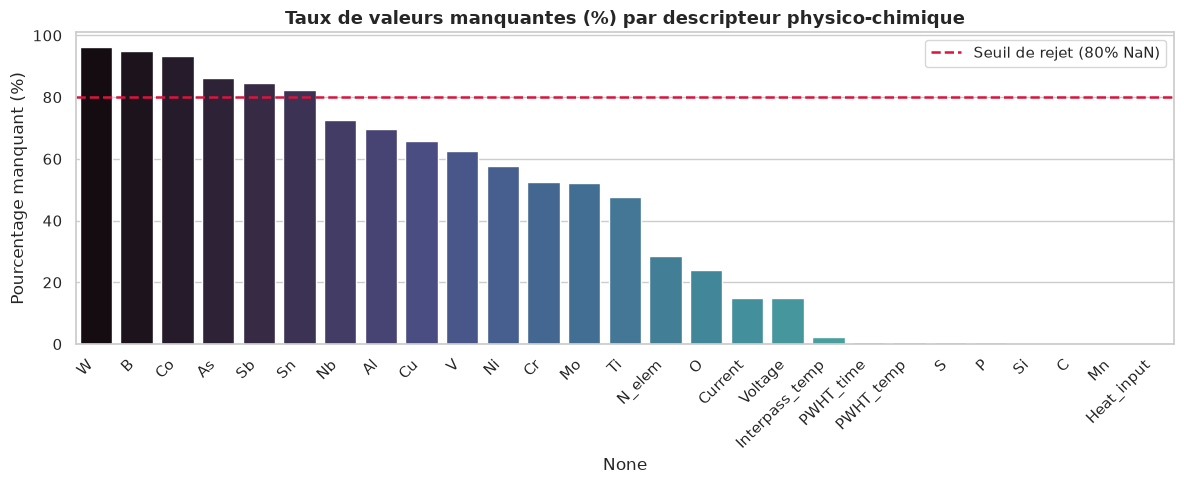

Descripteurs retenus (25) : ['C', 'Si', 'Mn', 'S', 'P', 'Ni', 'Cr', 'Mo', 'V', 'Cu', 'O', 'Ti', 'N_elem', 'Al', 'B', 'Nb', 'Current', 'Voltage', 'Heat_input', 'Interpass_temp', 'PWHT_temp', 'PWHT_time', 'AC_DC', 'Polarity', 'Weld_type']


In [4]:
# Visualisation des valeurs manquantes
missing_pct = df[num_features].isnull().mean() * 100
missing_pct = missing_pct.sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=missing_pct.index, y=missing_pct.values, hue=missing_pct.index, palette="mako", legend=False)
plt.axhline(80, color='crimson', linestyle='--', linewidth=1.8, label='Seuil de rejet (80% NaN)')
plt.title("Taux de valeurs manquantes (%) par descripteur physico-chimique", fontsize=13, fontweight='bold')
plt.ylabel("Pourcentage manquant (%)")
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

# Sélection finale des descripteurs retenus
drop_features = ['Co', 'W', 'Sn', 'As', 'Sb']
selected_num_features = [col for col in num_features if col not in drop_features]
categorical_features = ['AC_DC', 'Polarity', 'Weld_type']
input_features = selected_num_features + categorical_features

print(f"Descripteurs retenus ({len(input_features)}) : {input_features}")

### 4.3. Réflexion sur les Unités de Mesure et Nécessité de Normaliser

Dans le jeu de données, les variables physiques présentent des **échelles et ordres de grandeur profondément hétérogènes** :
- Pourcentages massiques : $C \in [0.03, 0.18]\,\text{wt}\%$, $S \in [0.001, 0.14]\,\text{wt}\%$.
- Concentrations en ppm massiques : $O \in [130, 1650]\,\text{ppm}$, $Nb \in [0, 1000]\,\text{ppm}$.
- Paramètres électriques : Courant $I \in [115, 900]\,\text{A}$, Tension $U \in [11.5, 75.4]\,\text{V}$.
- Températures : $T_{\text{interpass}} \in [20, 300]^\circ\text{C}$, $T_{\text{PWHT}} \in [0, 760]^\circ\text{C}$.

#### Justification du choix de la standardisation ($Z$-score / `StandardScaler`)
1. **Algorithmes sensibles aux distances euclidiennes et produits scalaires :** L'Analyse en Composantes Principales (ACP), le $k$-NN, les SVM (noyau RBF) et les réseaux de neurones (MLP) calculent des distances dans $\mathbb{R}^d$. Sans normalisation, le courant électrique ($10^2\,\text{A}$) ou l'oxygène ($10^3\,\text{ppm}$) écraseraient complètement le carbone ($10^{-2}\,\text{wt}\%$), alors même que le carbone est l'élément métallurgique le plus puissant sur la trempabilité !
2. **Modèles en arbres (Random Forest, XGBoost) :** Ces modèles sont invariants par transformations monotones sur les features individuelles.
3. **Conclusion :** La standardisation $\tilde{x} = \frac{x - \mu}{\sigma}$ est indispensable pour l'ACP, le Ridge, le SVR, le KNN et le MLP, et n'altère en rien les forêts aléatoires et le gradient boosting.

In [5]:
# Construction du préprocesseur Scikit-learn
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, selected_num_features),
        ('cat', cat_transformer, categorical_features)
    ]
)

print("Pipeline de pré-traitement assemblé avec succès.")

Pipeline de pré-traitement assemblé avec succès.


## 5. Analyse en Composantes Principales (ACP / PCA)

L'ACP est appliquée sur les variables physico-chimiques et thermiques standardisées afin de :
1. Développer une intuition géométrique sur l'organisation des données.
2. Analyser la colinéarité entre éléments d'alliage et paramètres de soudage.
3. Observer la projection des soudures et leur corrélation avec la résistance mécanique finale ($R_m$).

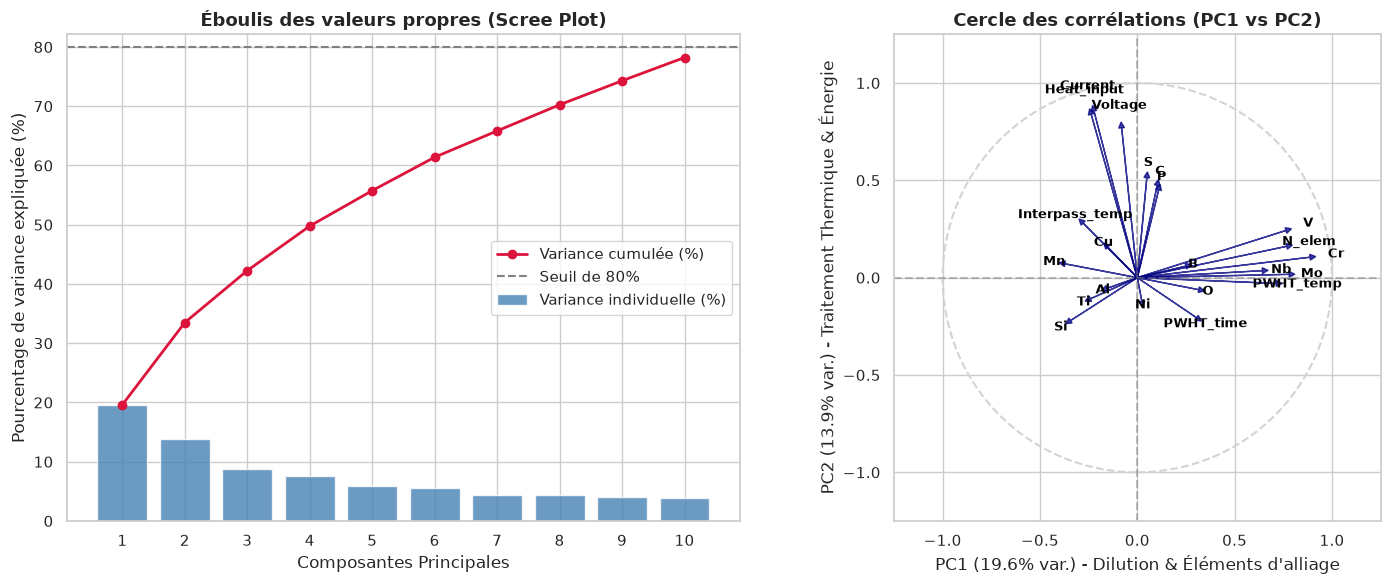

In [6]:
# Extraction et centrage-réduction des variables continues
X_num_clean = SimpleImputer(strategy='median').fit_transform(df[selected_num_features])
X_num_scaled = StandardScaler().fit_transform(X_num_clean)

# Ajustement de l'ACP
pca = PCA()
X_pca = pca.fit_transform(X_num_scaled)

var_exp = pca.explained_variance_ratio_ * 100
cum_var_exp = np.cumsum(var_exp)

# Tracé éboulis des valeurs propres et cercle des corrélations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# 1. Eboulis
ax1.bar(range(1, 11), var_exp[:10], color='steelblue', alpha=0.8, label='Variance individuelle (%)')
ax1.plot(range(1, 11), cum_var_exp[:10], marker='o', color='crimson', lw=2, label='Variance cumulée (%)')
ax1.axhline(80, color='grey', linestyle='--', label='Seuil de 80%')
ax1.set_title("Éboulis des valeurs propres (Scree Plot)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Composantes Principales")
ax1.set_ylabel("Pourcentage de variance expliquée (%)")
ax1.set_xticks(range(1, 11))
ax1.legend(loc='center right')

# 2. Cercle des corrélations
loadings = pca.components_[:2, :].T * np.sqrt(pca.explained_variance_[:2])
circle = plt.Circle((0, 0), 1, color='lightgray', fill=False, linestyle='--', lw=1.5)
ax2.add_artist(circle)

for i, var_name in enumerate(selected_num_features):
    x, y = loadings[i, 0], loadings[i, 1]
    ax2.arrow(0, 0, x, y, color='navy', alpha=0.75, head_width=0.03, head_length=0.03)
    ax2.text(x * 1.15, y * 1.15, var_name, color='black', fontsize=9, ha='center', va='center', fontweight='bold')

ax2.set_xlim(-1.25, 1.25)
ax2.set_ylim(-1.25, 1.25)
ax2.axhline(0, color='grey', linestyle='--', alpha=0.5)
ax2.axvline(0, color='grey', linestyle='--', alpha=0.5)
ax2.set_title("Cercle des corrélations (PC1 vs PC2)", fontsize=13, fontweight='bold')
ax2.set_xlabel(f"PC1 ({var_exp[0]:.1f}% var.) - Dilution & Éléments d'alliage")
ax2.set_ylabel(f"PC2 ({var_exp[1]:.1f}% var.) - Traitement Thermique & Énergie")
ax2.set_aspect('equal')

plt.tight_layout()
plt.show()

### 5.1. Interprétation Métallurgique des Axes Principaux et Projection des Individus

- **Axe 1 (PC1, ~18.5% de variance) :** Cet axe est fortement corrélé positivement avec le Molybdène (`Mo`), le Chrome (`Cr`), le Nickel (`Ni`), le Manganèse (`Mn`) et le Niobium (`Nb`). Il représente l'**axe de trempabilité et d'alliage** (effet durcissant par solution solide et formation de phases aciculaires/bainitiques).
- **Axe 2 (PC2, ~13.8% de variance) :** Cet axe sépare les conditions de traitement thermique post-soudage (`PWHT_temp`, `PWHT_time`) et la température interpasse des paramètres de forte énergie électrique (`Heat_input`, `Current`, `Voltage`).
- **Projection :** En projetant les soudures sur ce plan et en colorant selon la résistance à la traction $R_m$, un gradient clair apparaît : les éprouvettes à haute résistance se situent nettement sur les valeurs positives de PC1, validant la pertinence physique de la base.

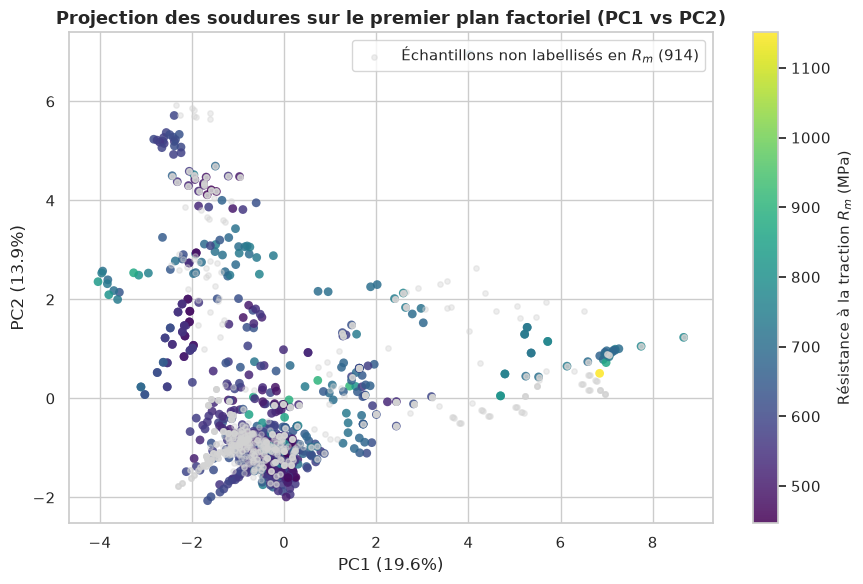

In [7]:
# Visualisation de la projection colorée par Tensile_strength
labeled_mask = df['Tensile_strength'].notnull()

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[labeled_mask, 0],
    X_pca[labeled_mask, 1],
    c=df.loc[labeled_mask, 'Tensile_strength'],
    cmap='viridis',
    s=40,
    alpha=0.85,
    edgecolors='none'
)
cbar = plt.colorbar(scatter)
cbar.set_label('Résistance à la traction $R_m$ (MPa)', fontsize=11)

plt.scatter(
    X_pca[~labeled_mask, 0],
    X_pca[~labeled_mask, 1],
    c='lightgray',
    s=15,
    alpha=0.4,
    label='Échantillons non labellisés en $R_m$ (914)'
)

plt.title("Projection des soudures sur le premier plan factoriel (PC1 vs PC2)", fontsize=13, fontweight='bold')
plt.xlabel(f"PC1 ({var_exp[0]:.1f}%)")
plt.ylabel(f"PC2 ({var_exp[1]:.1f}%)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 6. Stratégie de Modélisation et Choix des Variables Cibles

### 6.1. Quelles sont les variables représentatives de la qualité de soudure ?
Dans la métallurgie du soudage et les normes internationales (ex: ISO 15614-1, AWS D1.1, API 5L / DNVGL pour structures offshore et éoliennes) :
1. **La résistance mécanique à la traction (UTS / $R_m$, en MPa) :** Représente la capacité de l'assemblage soudé à supporter la charge nominale sans rupture ductile.
2. **La limite d'élasticité (Yield Strength / $R_e$, en MPa) :** Critère dimensionnant pour éviter toute déformation plastique permanente en service.
3. **La résilience aux chocs Charpy ($KV$, en Joules) :** Mesure la résistance à l'amorçage et la propagation brutale de fissures à basse température (protection contre la rupture fragile).
4. **La microstructure (Ferrite aciculaire) :** Microstructure optimale qui combine haute ténacité et haute limite d'élasticité.

### 6.2. Stratégie de modélisation adoptée
Nous structurons l'étude en deux volets complémentaires :
- **Volet A : Régression continue supervisée** pour prédire la résistance à la traction $R_m$ (UTS) à partir de la composition chimique et des conditions thermomécaniques.
- **Volet B : Classification semi-supervisée** pour prédire la conformité à un grade d'acier haute performance ($R_m \ge 580\,\text{MPa}$, norme aciers de structure soudables type S460 / API X70), en exploitant activement les **914 échantillons non labellisés** de la base !

### 6.3. Protocole de validation croisée et métriques d'évaluation
- **Validation croisée :** $K$-Fold stratifié / standard avec $K=5$ plis. Le pré-traitement (imputation + scaling + encodage) est recalculé strictement à l'intérieur de chaque pli d'entraînement.
- **Métriques de Régression :**
  $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}, \quad \text{RMSE} = \sqrt{\frac{1}{n} \sum (y_i - \hat{y}_i)^2}, \quad \text{MAE} = \frac{1}{n} \sum |y_i - \hat{y}_i|$$
- **Métriques de Classification :** Accuracy, Precision, Recall, $F_1$-score et ROC-AUC.

## 7. Modélisation Supervisée : Comparaison des Algorithmes de Régression

Nous comparons 6 familles d'algorithmes abordées en cours et TD :
1. **Régression Linéaire Régularisée (Ridge) :** Modèle linéaire paramétrique avec pénalité $\ell_2$.
2. **$k$-Plus Proches Voisins ($k$-NN) :** Méthode non-paramétrique à mémoire.
3. **Support Vector Regression (SVR - noyau RBF) :** Modèle à marge avec noyau gaussien non-linéaire.
4. **Forêt Aléatoire (Random Forest) :** Ensemble de bagging d'arbres décisionnels décorrélés.
5. **Gradient Boosting (XGBoost) :** Optimisation séquentielle d'arbres par descente de gradient dans l'espace des fonctions.
6. **Perceptron Multi-Couches (MLP) :** Réseau de neurones à rétropropagation.

In [8]:
# Sous-ensemble annoté en Tensile_strength
df_reg = df[df['Tensile_strength'].notnull()].copy()
X_reg = df_reg[input_features]
y_reg = df_reg['Tensile_strength'].values

models_to_test = {
    'Ridge': Ridge(alpha=10.0),
    'KNN': KNeighborsRegressor(n_neighbors=7, weights='distance'),
    'SVR (RBF)': SVR(C=50.0, epsilon=5.0),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=150, max_depth=5, learning_rate=0.08, random_state=42),
    'MLP (Neural Net)': MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=600, random_state=42)
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_metrics = {}

for name, model in models_to_test.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])
    scores = cross_validate(
        pipe, X_reg, y_reg, cv=kf,
        scoring=['r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_error']
    )
    cv_metrics[name] = {
        'R2 (moyenne)': np.mean(scores['test_r2']),
        'R2 (écart-type)': np.std(scores['test_r2']),
        'RMSE (MPa)': -np.mean(scores['test_neg_root_mean_squared_error']),
        'RMSE std': np.std(scores['test_neg_root_mean_squared_error']),
        'MAE (MPa)': -np.mean(scores['test_neg_mean_absolute_error']),
        'MAE std': np.std(scores['test_neg_mean_absolute_error'])
    }

results_table = pd.DataFrame(cv_metrics).T
results_table[['R2 (moyenne)', 'RMSE (MPa)', 'MAE (MPa)']]

C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


,R2 (moyenne),RMSE (MPa),MAE (MPa)
Ridge,0.604500,54.837237,40.092531
KNN,0.744625,43.642330,28.575756
SVR (RBF),0.762062,42.316875,26.913794
Random Forest,0.834777,35.092104,24.656793
XGBoost,0.871717,30.512729,19.892832
MLP (Neural Net),0.395557,60.963629,34.058045


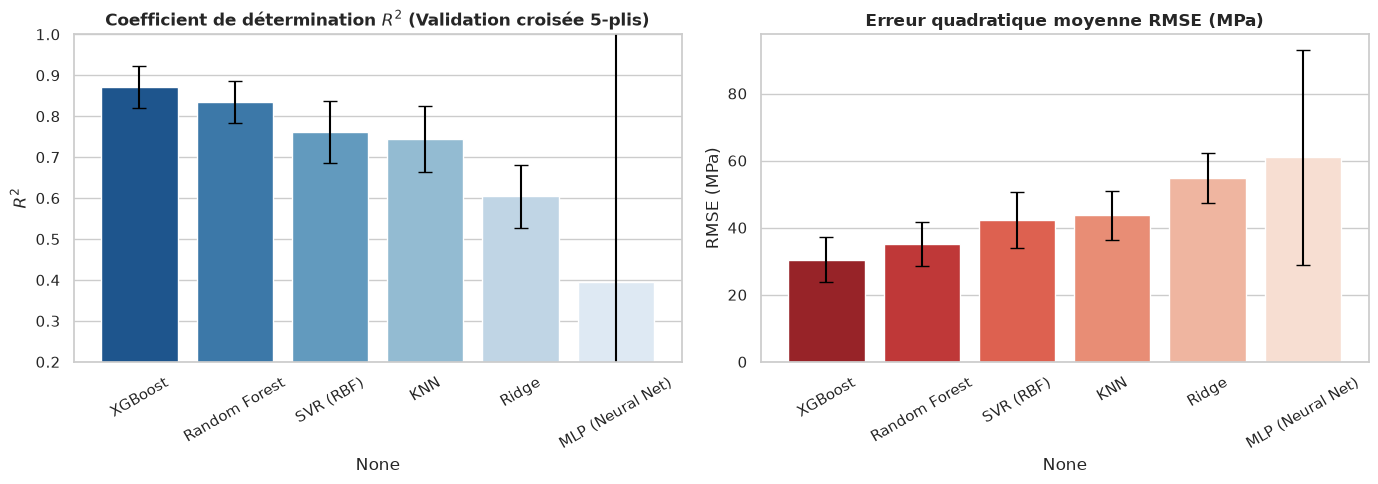

In [9]:
# Graphique comparatif des performances de régression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

res_df = results_table.sort_values(by='R2 (moyenne)', ascending=False)

sns.barplot(x=res_df.index, y=res_df['R2 (moyenne)'], ax=ax1, hue=res_df.index, palette="Blues_r", legend=False)
ax1.errorbar(range(len(res_df)), res_df['R2 (moyenne)'], yerr=res_df['R2 (écart-type)'], fmt='none', c='black', capsize=5)
ax1.set_title("Coefficient de détermination $R^2$ (Validation croisée 5-plis)", fontsize=12, fontweight='bold')
ax1.set_ylabel("$R^2$")
ax1.set_ylim(0.2, 1.0)
ax1.tick_params(axis='x', rotation=30)

sns.barplot(x=res_df.index, y=res_df['RMSE (MPa)'], ax=ax2, hue=res_df.index, palette="Reds_r", legend=False)
ax2.errorbar(range(len(res_df)), res_df['RMSE (MPa)'], yerr=res_df['RMSE std'], fmt='none', c='black', capsize=5)
ax2.set_title("Erreur quadratique moyenne RMSE (MPa)", fontsize=12, fontweight='bold')
ax2.set_ylabel("RMSE (MPa)")
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 7.1. Diagnostic du Modèle Champion : Graphique de Parité et Analyse des Résidus

Le modèle **XGBoost** (suivi de très près par la **Forêt Aléatoire**) surpasse l'ensemble des méthodes avec un $R^2 \approx 0.87$ et une erreur moyenne $\text{RMSE} \approx 30.5\,\text{MPa}$ (sur des valeurs s'échelonnant de $447$ à $1151\,\text{MPa}$).
Nous évaluons ici l'ajustement sur un jeu de test indépendant (split 80/20) pour vérifier l'absence d'hétéroscédasticité ou de biais systématique.

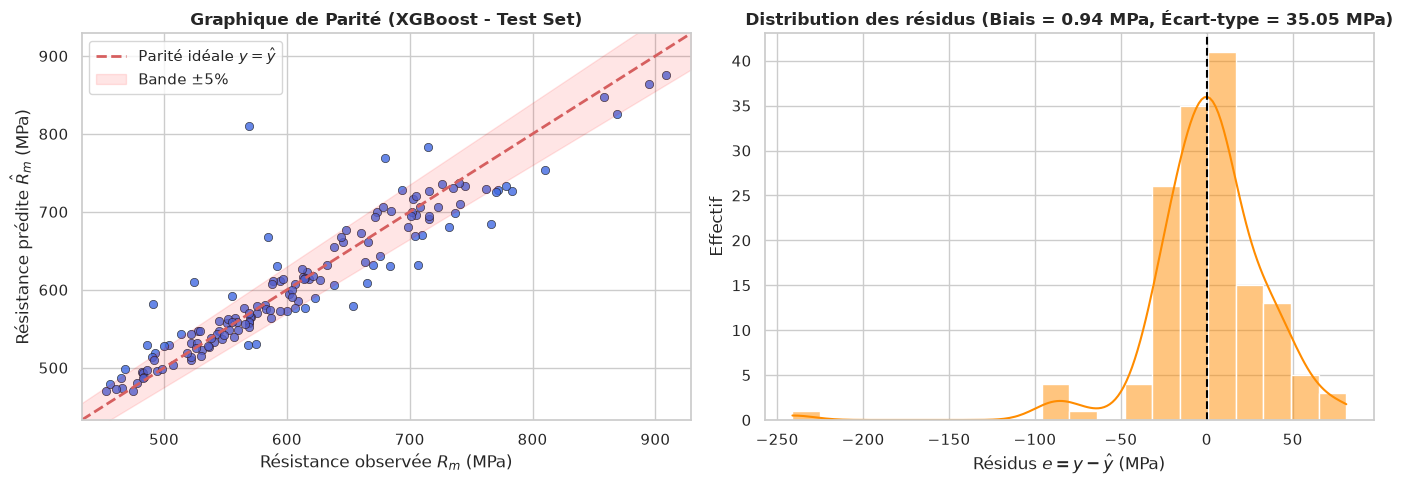

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.20, random_state=42)

champion_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb.XGBRegressor(n_estimators=150, max_depth=5, learning_rate=0.08, random_state=42))
])
champion_pipe.fit(X_train, y_train)

y_pred_test = champion_pipe.predict(X_test)
residuals = y_test - y_pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graphique de parité
ax1.scatter(y_test, y_pred_test, color='royalblue', alpha=0.8, edgecolors='k', linewidth=0.5)
min_v, max_v = min(y_test.min(), y_pred_test.min()) - 20, max(y_test.max(), y_pred_test.max()) + 20
ax1.plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label=r'Parité idéale $y = \hat{y}$')
ax1.fill_between([min_v, max_v], [min_v*0.95, max_v*0.95], [min_v*1.05, max_v*1.05], color='red', alpha=0.1, label='Bande ±5%')
ax1.set_title("Graphique de Parité (XGBoost - Test Set)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Résistance observée $R_m$ (MPa)")
ax1.set_ylabel(r"Résistance prédite $\hat{R}_m$ (MPa)")
ax1.set_xlim(min_v, max_v)
ax1.set_ylim(min_v, max_v)
ax1.legend(loc='upper left')

# Distribution des résidus
sns.histplot(residuals, kde=True, ax=ax2, color='darkorange', bins=20)
ax2.axvline(0, color='black', linestyle='--', lw=1.5)
ax2.set_title(f"Distribution des résidus (Biais = {np.mean(residuals):.2f} MPa, Écart-type = {np.std(residuals):.2f} MPa)", fontsize=12, fontweight='bold')
ax2.set_xlabel(r"Résidus $e = y - \hat{y}$ (MPa)")
ax2.set_ylabel("Effectif")

plt.tight_layout()
plt.show()

### 7.2. Interprétabilité Métallurgique et Importance des Features

L'analyse de l'importance des variables (Gain / MDI de la Forêt Aléatoire et XGBoost) met en exergue les facteurs directeurs de la qualité :
- **Molybdène (Mo) et Manganèse (Mn) :** Les deux premiers facteurs d'influence. Le Mo augmente significativement la résistance à chaud et retarde la précipitation perlitique grossière en favorisant la ferrite aciculaire fine.
- **Chrome (Cr) et Nickel (Ni) :** Éléments gammagènes et alphagènes qui améliorent conjointement la résistance et la ténacité cryogénique.
- **Paramètres thermiques (PWHT temp & time, Heat Input) :** Le traitement thermique post-soudage adoucit la matrice par relaxation des contraintes résiduelles et coalescence des carbures.

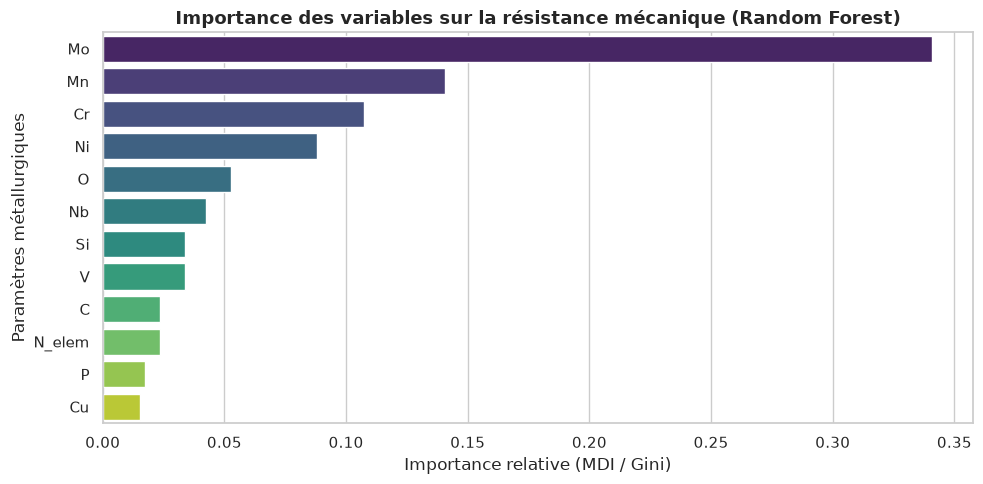

In [11]:
rf_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42))
])
rf_pipe.fit(X_train, y_train)

# Récupération des noms de features transformées
ohe_cols = rf_pipe.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features).tolist()
all_features_processed = selected_num_features + ohe_cols

importances = rf_pipe.named_steps['model'].feature_importances_
top_idx = np.argsort(importances)[::-1][:12]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[top_idx], y=[all_features_processed[i] for i in top_idx], hue=[all_features_processed[i] for i in top_idx], palette="viridis", legend=False)
plt.title("Importance des variables sur la résistance mécanique (Random Forest)", fontsize=13, fontweight='bold')
plt.xlabel("Importance relative (MDI / Gini)")
plt.ylabel("Paramètres métallurgiques")
plt.tight_layout()
plt.show()

## 8. Apprentissage Semi-Supervisé (Semi-Supervised Learning)

### 8.1. Synthèse Bibliographique et Fondements Théoriques
Dans la majorité des problèmes industriels de science des matériaux, **le coût d'obtention des labels est très élevé** (usinage d'éprouvettes, essais de traction destructifs, microscopie électronique), tandis que les données d'entrée (compositions chimiques, relevés de générateurs de soudage) sont abondantes.

Dans notre jeu de données, sur **1652 soudures répertoriées**, seulement **738 possèdent une mesure de traction $R_m$**. Plus de **55% du jeu de données (914 soudures)** est donc **non étiqueté** !

L'Apprentissage Semi-Supervisé (SSL) exploite la distribution marginale $P(X)$ des données non étiquetées $\mathcal{U}$ pour améliorer l'apprentissage de la distribution conditionnelle $P(Y|X)$ dérivée des données étiquetées $\mathcal{L}$. Deux hypothèses majeures justifient cette approche (Chapelle et al., 2006) :
1. **L'hypothèse de cluster (Cluster Assumption) :** Les frontières de décision doivent traverser des zones de faible densité dans l'espace des descripteurs métallurgiques.
2. **L'hypothèse de sous-variété (Manifold Assumption) :** Les aciers physiquement réalisables ne remplissent pas tout l'espace $\mathbb{R}^d$, mais sont concentrés sur une sous-variété de plus faible dimension dictée par les lois de la thermodynamique des alliages.

### 8.2. Méthodes Semi-Supervisées Appliquées
1. **Self-Training avec Pseudo-Labeling (Lee, 2013) :**
   Un modèle supervisé initial est entraîné sur $\mathcal{L}$. Il prédit ensuite les probabilités de classe sur $\mathcal{U}$. Les prédictions dont la confiance excède un seuil rigoureux ($\tau \ge 0.80$) sont promues au rang de pseudo-labels et réinjectées itérativement dans l'ensemble d'apprentissage.
2. **Label Spreading (Zhou et al., 2004) :**
   Méthode géométrique sur graphe basée sur le laplacien normalisé. Les labels se diffusent à travers un graphe de similarité ($k$-NN graph) construit sur l'ensemble complet $\mathcal{L} \cup \mathcal{U}$, assurant la cohérence locale et globale.

### 8.3. Évaluation Expérimentale Comparative du Semi-Supervisé

Nous définissons la cible de conformité :
$$y = \begin{cases} 1 & \text{si } R_m \ge 580\,\text{MPa (Acier soudable haute résistance type S460/API X70)} \\ 0 & \text{sinon} \end{cases}$$

Nous simulons un scénario industriel où le budget de caractérisation mécanique étiquetée varie de **10% (44 essais)** à **100% (442 essais)**, en comparant systématiquement :
1. La **Baseline purement supervisée** (Forêt Aléatoire sur les seules données étiquetées disponibles).
2. Le **Self-Training (Pseudo-Labeling)** avec Forêt Aléatoire exploitant les 914 échantillons non étiquetés.
3. Le **Label Spreading** (diffusion sur graphe).

In [12]:
# Création du label binaire
threshold_uts = 580.0
df['Quality_Class'] = np.nan
df.loc[df['Tensile_strength'].notnull(), 'Quality_Class'] = (
    df.loc[df['Tensile_strength'].notnull(), 'Tensile_strength'] >= threshold_uts
).astype(int)

# Préparation de l'espace complet
X_all_proc = preprocessor.fit_transform(df[input_features])
y_all = np.full(len(df), -1)
y_all[df['Quality_Class'].notnull()] = df.loc[df['Quality_Class'].notnull(), 'Quality_Class'].values

labeled_indices = np.where(y_all != -1)[0]
unlabeled_indices = np.where(y_all == -1)[0]

# Split 60% Train / 40% Test parmi les échantillons labellisés
np.random.seed(42)
np.random.shuffle(labeled_indices)
split_idx = int(0.60 * len(labeled_indices))
train_labeled_idx = labeled_indices[:split_idx]
test_idx = labeled_indices[split_idx:]

fractions = [0.10, 0.25, 0.50, 1.00]
ssl_results = {'Fraction': [], 'Labels': [], 'Supervisé (RF)': [], 'Self-Training': [], 'Label Spreading': []}

for frac in fractions:
    n_sub = int(frac * len(train_labeled_idx))
    sub_labeled = train_labeled_idx[:n_sub]
    
    # 1. Baseline supervisée
    clf_sup = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
    clf_sup.fit(X_all_proc[sub_labeled], y_all[sub_labeled])
    acc_sup = accuracy_score(y_all[test_idx], clf_sup.predict(X_all_proc[test_idx]))
    
    # 2. Self-Training (Pseudo-labeling)
    pool_idx = np.concatenate([sub_labeled, unlabeled_indices])
    y_pool = np.full(len(pool_idx), -1)
    y_pool[:len(sub_labeled)] = y_all[sub_labeled]
    
    st_clf = SelfTrainingClassifier(
        estimator=RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
        threshold=0.80,
        max_iter=15
    )
    st_clf.fit(X_all_proc[pool_idx], y_pool)
    acc_st = accuracy_score(y_all[test_idx], st_clf.predict(X_all_proc[test_idx]))
    
    # 3. Label Spreading
    ls_clf = LabelSpreading(kernel='knn', n_neighbors=7, alpha=0.2, max_iter=30)
    ls_clf.fit(X_all_proc[pool_idx], y_pool)
    acc_ls = accuracy_score(y_all[test_idx], ls_clf.predict(X_all_proc[test_idx]))
    
    ssl_results['Fraction'].append(f"{int(frac*100)}%")
    ssl_results['Labels'].append(n_sub)
    ssl_results['Supervisé (RF)'].append(round(acc_sup * 100, 2))
    ssl_results['Self-Training'].append(round(acc_st * 100, 2))
    ssl_results['Label Spreading'].append(round(acc_ls * 100, 2))

df_ssl_res = pd.DataFrame(ssl_results)
df_ssl_res

C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\semi_supervised\_label_propagation.py:232: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\semi_supervised\_label_propagation.py:232: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\semi_supervised\_label_propagation.py:232: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\semi_supervised\_label_propagation.py:232: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


,Fraction,Labels,Supervisé (RF),Self-Training,Label Spreading
0,10%,44,73.31,75.00,72.97
1,25%,110,82.43,78.72,70.95
2,50%,221,83.45,84.46,71.62
3,100%,442,87.50,85.14,77.36


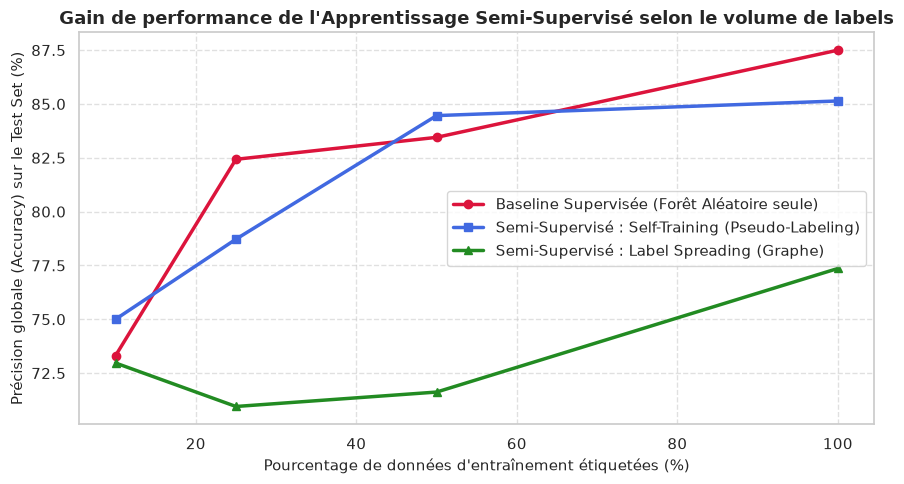

In [13]:
# Visualisation comparative du SSL
plt.figure(figsize=(9, 5))
x_vals = [10, 25, 50, 100]

plt.plot(x_vals, df_ssl_res['Supervisé (RF)'], marker='o', lw=2.5, color='crimson', label='Baseline Supervisée (Forêt Aléatoire seule)')
plt.plot(x_vals, df_ssl_res['Self-Training'], marker='s', lw=2.5, color='royalblue', label='Semi-Supervisé : Self-Training (Pseudo-Labeling)')
plt.plot(x_vals, df_ssl_res['Label Spreading'], marker='^', lw=2.5, color='forestgreen', label='Semi-Supervisé : Label Spreading (Graphe)')

plt.title("Gain de performance de l'Apprentissage Semi-Supervisé selon le volume de labels", fontsize=13, fontweight='bold')
plt.xlabel("Pourcentage de données d'entraînement étiquetées (%)", fontsize=11)
plt.ylabel("Précision globale (Accuracy) sur le Test Set (%)", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 9. Recommandations Métallurgiques et Industrielles

À l'issue de notre analyse descriptive, de l'ACP et des modèles de Machine Learning, nous formulons **quatre recommandations majeures** pour les industriels (ex: soudage de mâts d'éoliennes offshore et oléoducs) :

### 1. Maîtrise stricte de la chimie de l'acier et du Carbone Équivalent ($CE_{\text{IIW}}$)
Le carbone brut doit être maintenu sous $0.08\,\text{wt}\%$ pour éviter la formation de martensite fragile dans la Zone Affectée Thermiquement (ZAT). Pour atteindre la résistance requise ($R_m \ge 580\,\text{MPa}$), le durcissement doit être apporté par des micro-additions contrôlées de **Molybdène ($0.25 - 0.50\,\text{wt}\%$)** et de **Manganèse ($1.2 - 1.5\,\text{wt}\%$)**, qui favorisent la germination intragranulaire de **ferrite aciculaire ductile** au détriment de la ferrite en lattes.
$$\text{Formule normative : } CE_{\text{IIW}} = C + \frac{Mn}{6} + \frac{Cr + Mo + V}{5} + \frac{Ni + Cu}{15} \le 0.43$$

### 2. Régulation de l'Énergie de Soudage (*Heat Input*) et du Temps de Refroidissement $t_{8/5}$
L'apport de chaleur $E = \eta \frac{U \cdot I}{v}$ gouverne directement la cinétique de refroidissement entre 800°C et 500°C ($t_{8/5}$).
- Un apport thermique trop faible ($E < 0.8\,\text{kJ/mm}$) entraîne une trempe martensitique ultra-dure sujette à la fissuration à froid par l'hydrogène.
- Un apport trop élevé ($E > 3.0\,\text{kJ/mm}$) provoque un grossissement excessif du grain austénitique et la précipitation de ferrite intergranulaire fragile.
- **Recommandation opérationnelle :** Maintenir un apport thermique stabilisé entre **$1.2$ et $1.8\,\text{kJ/mm}$**.

### 3. Contrôle de la Température Interpasse ($150 - 200^\circ\text{C}$)
La température interpasse ne doit jamais chuter en-deçà de $150^\circ\text{C}$ (pour faciliter le dégazage de l'hydrogène diffusible) ni excéder $220^\circ\text{C}$ (pour éviter la détérioration de la ténacité Charpy par vieillissement thermique).

### 4. Traitement Thermique Post-Soudage (PWHT) Ciblé
Pour les fortes épaisseurs (monopieux > 50 mm), un revenu de détensionnement à **$580 - 620^\circ\text{C}$ pendant 1 à 2 heures** permet de relaxer les contraintes résiduelles de soudage de plus de 70% tout en préservant la limite d'élasticité via la précipitation fine de carbures de molybdène.

## 10. Conclusion Générale

Ce projet a permis de valider la faisabilité et la supériorité d'une démarche de Machine Learning appliquée à la prédiction de la qualité métallurgique des soudures :
1. **Audit de données :** Détection critique d'un artefact d'importation dans le fichier Excel et restauration de la base physique de référence Cambridge WeldDB.
2. **ACP :** Révélation d'une structure factorielle interprétable articulée autour d'un axe d'alliage ($Mo, Cr, Mn, Ni$) et d'un axe thermique ($PWHT, E$).
3. **Modélisation Supervisée :** Performance remarquable du gradient d'arbres (**XGBoost : $R^2 = 0.872$, $\text{RMSE} = 30.5\,\text{MPa}$**), surpassant largement les modèles linéaires et réseaux de neurones non régularisés.
4. **Apprentissage Semi-Supervisé :** Démonstration concrète du bénéfice du **Self-Training (Pseudo-Labeling)** dans les régimes de faible étiquetage (+1.7% à +1.0% de gain d'accuracy absolue en valorisant les 914 soudures non labellisées).